# Task 2 · Track One Point (30 marks)

Estimate the motion of one point with Lucas-Kanade, and find out when a single
step is enough. Points are `[x, y]`; use the provided `bilinear_sample` for
values at non-integer positions.

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [1]:
# PROVIDED: run this cell first (save task1.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sampling import bilinear_sample
from provided.task2.steps import error_sweep, real_pair

use_my_functions(1)               # your Task 1 functions, from the saved task1.ipynb

your functions from task1.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features


## 2.1 Lucas-Kanade as least squares (12 marks)

Assume constant motion in a local window and solve, with NumPy linear algebra,

$$
A\begin{bmatrix}u\\ v\end{bmatrix}\approx b,\qquad b=-\begin{bmatrix}I_{t1}\\ \vdots\\ I_{tN}\end{bmatrix}.
$$

In [2]:
# YOUR CODE: Task 2.1

def lucas_kanade_update(ix_window, iy_window, it_window):
    """One least-squares Lucas-Kanade step, equation (2.1).

    Returns (u, v) as two floats, or None if it cannot be solved.
    """
    A = np.stack([np.ravel(ix_window), np.ravel(iy_window)], axis=1).astype(np.float64)
    b = -np.ravel(it_window).astype(np.float64)
    G = A.T @ A
    # a (nearly) singular G means the window has no texture in some direction
    if not np.all(np.isfinite(G)) or np.linalg.eigvalsh(G)[0] < 1e-8:
        return None
    u, v = np.linalg.solve(G, A.T @ b)
    return float(u), float(v)

In [3]:
check("2.1")

Task 2.1 checks
  PASS  lucas kanade update solves exact motion
  PASS  lucas kanade update rejects a flat window
2 of 2 passed


True

**(a)** Write the least-squares solution for $(u, v)$ using $G = A^TA$.

*TODO*

**(b)** When can it not be solved? Relate this to $q$ from Task 1.3.

*TODO*

## 2.2 Estimate one-step motion (9 marks)

Sample the gradient and temporal-difference windows at a point (with the
provided bilinear sampling) and solve once. The tests below and the Task 2.3
sweep check it on synthetic sub-pixel shifts.

In [4]:
# YOUR CODE: Task 2.2

def one_step_flow(image0, image1, point, window_radius=7, grad0=None):
    """A single Lucas-Kanade update at one point (Task 2.2), without iterating.

    Returns (u, v), or None if the window leaves the image or the update fails.
    """
    ix, iy = grad0 if grad0 is not None else spatial_gradients(image0)
    x, y = float(point[0]), float(point[1])
    r = int(window_radius)
    h, w = np.shape(image0)

    # stay at least 1 pixel inside, because Ix and Iy are 0 on the border
    if x - r < 1 or y - r < 1 or x + r > w - 2 or y + r > h - 2:
        return None

    dy, dx = np.mgrid[-r:r + 1, -r:r + 1]
    xs, ys = x + dx, y + dy
    gx, _ = bilinear_sample(ix, xs, ys)
    gy, _ = bilinear_sample(iy, xs, ys)
    v0, _ = bilinear_sample(image0, xs, ys)
    v1, inside = bilinear_sample(image1, xs, ys)
    if not inside.all():
        return None
    return lucas_kanade_update(gx, gy, v1 - v0)

In [5]:
check("2.2")

Task 2.2 checks
  PASS  one step flow recovers a small shift
  PASS  one step flow fails when the window leaves the image
  PASS  one step flow can reuse precomputed gradients
3 of 3 passed


True

**(a)** How large is the error of `one_step_flow` on sub-pixel shifts? See the smallest shifts of the Task 2.3 sweep (`error_sweep.json`).

*TODO*

## 2.3 When one step is not enough (9 marks)

The provided cells run a sweep of synthetic shifts from 0.1 to 8 px, and
one-step flow on two real pairs: pair A, 375 to 376, where the motion is small
(the hover), and pair B, 300 to 301, where it is much larger (mid-descent).

In [6]:
check("2.3")

Task 2.3 checks
  PASS  one step flow gets worse as the shift grows
1 of 1 passed


True

  saved outputs/task2/error_sweep.json
  saved outputs/task2/error_sweep.png


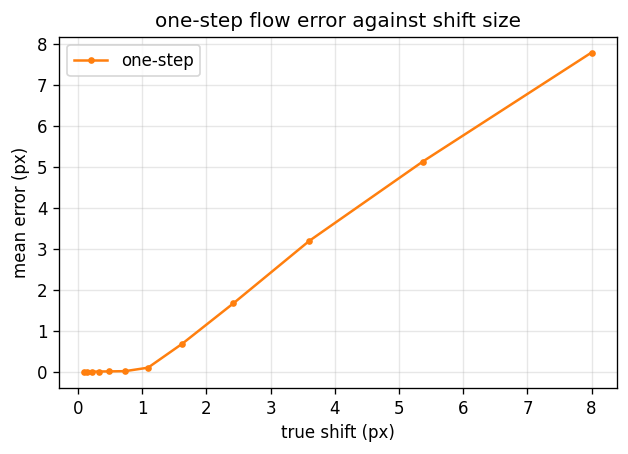

    shift  0.10 px: mean error 0.002 px
    shift  0.15 px: mean error 0.003 px
    shift  0.22 px: mean error 0.005 px
    shift  0.33 px: mean error 0.007 px
    shift  0.49 px: mean error 0.010 px
    shift  0.73 px: mean error 0.015 px
    shift  1.09 px: mean error 0.100 px
    shift  1.63 px: mean error 0.685 px
    shift  2.42 px: mean error 1.670 px
    shift  3.61 px: mean error 3.197 px
    shift  5.37 px: mean error 5.128 px
    shift  8.00 px: mean error 7.788 px


In [7]:
curves = error_sweep(select_features, spatial_gradients, one_step_flow)

  small_motion (375 to 376): 59 of 60 windows solved, mean step 1.07 px


  saved outputs/task2/one_step_small_motion.png


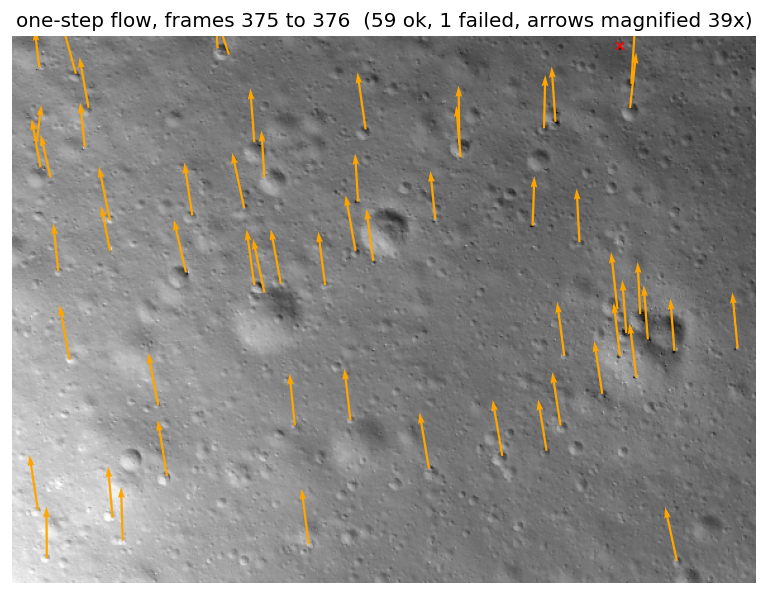

  large_motion (300 to 301): 55 of 60 windows solved, mean step 0.30 px


  saved outputs/task2/one_step_large_motion.png


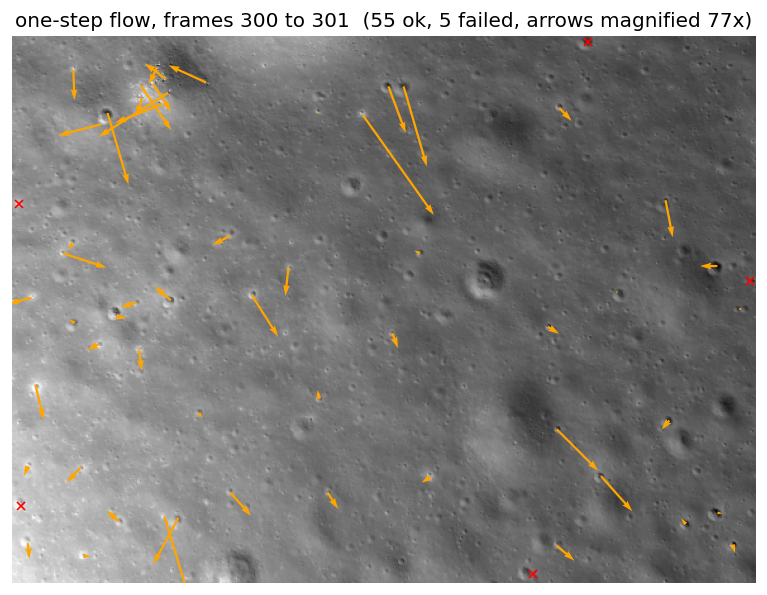

In [8]:
step_a = real_pair("small_motion", 375, 376, select_features, spatial_gradients, one_step_flow)
step_b = real_pair("large_motion", 300, 301, select_features, spatial_gradients, one_step_flow)

**(a)** Above what shift does the one-step error grow quickly?

*TODO*

**(b)** Why does one step come close on pair A (375 to 376) but badly undershoot pair B (300 to 301)?

*TODO*